In [ ]:
# ============================================================
# NEUROSCAN AI - Phase 2: 3D Tumor Segmentation (BraTS 2023 GLI)
# Cell 1: Install, GPU check, Drive, dataset access check
# ============================================================
!pip install -q monai nibabel huggingface_hub

import os, collections
import torch
from google.colab import drive
from huggingface_hub import HfApi

print("PyTorch:", torch.__version__)
print("GPU    :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch runtime to T4")

drive.mount("/content/drive")
WORK = "/content/drive/MyDrive/neuroscan-ai/segmentation"
os.makedirs(WORK, exist_ok=True)
print("Work folder:", WORK)

# ---------- Check the dataset is reachable (lists file names only, downloads nothing) ----------
REPO = "MedOtter/brats2023-gli-dataset"
api = HfApi()
files = api.list_repo_files(REPO, repo_type="dataset")
nii = [f for f in files if f.endswith(".nii.gz")]

case_ids = sorted({f.split("/")[-2] for f in nii})
patients = collections.defaultdict(list)
for c in case_ids:
    patients[c.rsplit("-", 1)[0]].append(c)

print(f"\nFiles listed        : {len(files)}")
print(f"NIfTI files         : {len(nii)}")
print(f"Cases (scans)       : {len(case_ids)}")
print(f"Unique patients     : {len(patients)}")
print(f"Patients with >1 scan: {sum(len(v) > 1 for v in patients.values())}")

first = case_ids[0]
print(f"\nFiles for case {first}:")
for f in nii:
    if f.split("/")[-2] == first:
        print("  ", f.split("/")[-1])

PyTorch: 2.11.0+cu130
GPU    : Tesla T4
Mounted at /content/drive
Work folder: /content/drive/MyDrive/neuroscan-ai/segmentation

Files listed        : 6258
NIfTI files         : 6255
Cases (scans)       : 1251
Unique patients     : 1133
Patients with >1 scan: 118

Files for case BraTS-GLI-00000-000:
   BraTS-GLI-00000-000-seg.nii.gz
   BraTS-GLI-00000-000-t1c.nii.gz
   BraTS-GLI-00000-000-t1n.nii.gz
   BraTS-GLI-00000-000-t2f.nii.gz
   BraTS-GLI-00000-000-t2w.nii.gz


ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 49.9kB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.64MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.33MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.53MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.43MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

Downloaded: ['seg', 't1c', 't1n', 't2f', 't2w']
t1n  shape=(240, 240, 155) dtype=int16 spacing=(1.0, 1.0, 1.0) orientation=LPS min=0.0 max=2023.0 nonzero=16.6%
t1c  shape=(240, 240, 155) dtype=int16 spacing=(1.0, 1.0, 1.0) orientation=LPS min=0.0 max=12343.0 nonzero=16.6%
t2w  shape=(240, 240, 155) dtype=int16 spacing=(1.0, 1.0, 1.0) orientation=LPS min=0.0 max=2421.0 nonzero=16.6%
t2f  shape=(240, 240, 155) dtype=int16 spacing=(1.0, 1.0, 1.0) orientation=LPS min=0.0 max=2934.0 nonzero=16.6%
seg  shape=(240, 240, 155) dtype=float32 spacing=(1.0, 1.0, 1.0) orientation=LPS min=0.0 max=3.0 nonzero=0.6%

Mask labels and voxel counts: {0: 8870695, 1: 11738, 2: 12836, 3: 32731}
  label 1 Necrotic core (NCR)   :   11.74 cm3
  label 2 Edema (ED)            :   12.84 cm3
  label 3 Enhancing tumor (ET)  :   32.73 cm3
  Whole tumor (WT)                 :   57.31 cm3


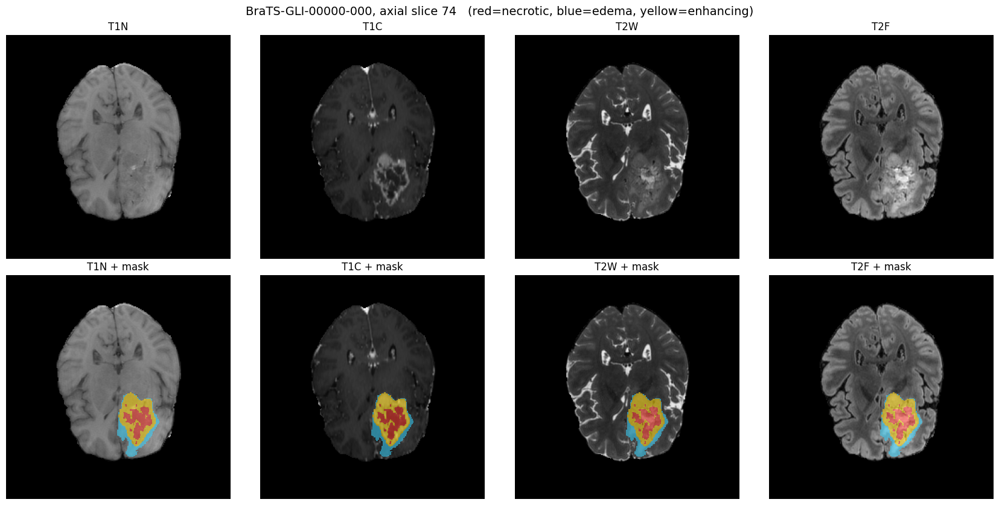

In [ ]:
# ============================================================
# Cell 2: Download one case and inspect volumes + mask
# ============================================================
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

DATA = "/content/brats"
os.makedirs(DATA, exist_ok=True)
CASE = case_ids[0]
MODS = ["t1n", "t1c", "t2w", "t2f"]

# ---------- 1) Download the 5 files of this case ----------
paths = {}
for f in nii:
    if f.split("/")[-2] == CASE:
        key = f.split("-")[-1].replace(".nii.gz", "")      # t1n / t1c / t2w / t2f / seg
        paths[key] = hf_hub_download(REPO, f, repo_type="dataset", local_dir=DATA)
print("Downloaded:", sorted(paths))

# ---------- 2) Load and describe ----------
vols = {k: nib.load(paths[k]) for k in MODS + ["seg"]}
for k, img in vols.items():
    data = img.get_fdata() if k != "seg" else np.asarray(img.dataobj)
    print(f"{k:4} shape={img.shape} dtype={img.get_data_dtype()} "
          f"spacing={tuple(round(float(z), 2) for z in img.header.get_zooms())} "
          f"orientation={''.join(nib.aff2axcodes(img.affine))} "
          f"min={data.min():.1f} max={data.max():.1f} "
          f"nonzero={(data != 0).mean():.1%}")

seg = np.asarray(vols["seg"].dataobj).astype(np.uint8)
vox_cm3 = np.prod(vols["seg"].header.get_zooms()) / 1000.0
labels, counts = np.unique(seg, return_counts=True)
print("\nMask labels and voxel counts:", dict(zip(labels.tolist(), counts.tolist())))
names = {1: "Necrotic core (NCR)", 2: "Edema (ED)", 3: "Enhancing tumor (ET)"}
for l in (1, 2, 3):
    print(f"  label {l} {names[l]:22}: {(seg == l).sum() * vox_cm3:7.2f} cm3")
print(f"  Whole tumor (WT)                 : {(seg > 0).sum() * vox_cm3:7.2f} cm3")

# ---------- 3) Plot the axial slice with the most tumor, in all 4 modalities ----------
z = int(np.argmax((seg > 0).sum(axis=(0, 1))))
cmap = plt.matplotlib.colors.ListedColormap(["none", "#ff3b30", "#39d5ff", "#ffd60a"])
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for ax, k in zip(axes[0], MODS):
    ax.imshow(np.rot90(vols[k].get_fdata()[:, :, z]), cmap="gray"); ax.set_title(k.upper()); ax.axis("off")
for ax, k in zip(axes[1], MODS):
    ax.imshow(np.rot90(vols[k].get_fdata()[:, :, z]), cmap="gray")
    ax.imshow(np.rot90(seg[:, :, z]), cmap=cmap, vmin=0, vmax=3, alpha=0.55, interpolation="nearest")
    ax.set_title(f"{k.upper()} + mask"); ax.axis("off")
plt.suptitle(f"{CASE}, axial slice {z}   (red=necrotic, blue=edema, yellow=enhancing)", fontsize=14)
plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# Cell 3: Choose 100 patients, patient-level split, parallel download
# ============================================================
import json, random, time, subprocess, collections
from concurrent.futures import ThreadPoolExecutor, as_completed
from huggingface_hub import HfApi, hf_hub_download

# Optional: use a free Hugging Face token stored in Colab Secrets (key icon, left side)
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("Using HF token from Colab Secrets")
except Exception:
    print("No HF token found (fine, downloads may just be slower)")

REPO = "MedOtter/brats2023-gli-dataset"
DATA = "/content/brats"
WORK = "/content/drive/MyDrive/neuroscan-ai/segmentation"
TAR = f"{WORK}/brats_subset.tar"
N_PATIENTS, SEED = 100, 42

# ---------- 1) Map every case to its 5 repo files ----------
files = [f for f in HfApi().list_repo_files(REPO, repo_type="dataset") if f.endswith(".nii.gz")]
case_files = collections.defaultdict(dict)
for f in files:
    case_files[f.split("/")[-2]][f.split("-")[-1].replace(".nii.gz", "")] = f
complete = {c: v for c, v in case_files.items() if set(v) == {"t1n", "t1c", "t2w", "t2f", "seg"}}
print(f"Complete cases: {len(complete)} of {len(case_files)}")

patients = collections.defaultdict(list)
for c in sorted(complete):
    patients[c.rsplit("-", 1)[0]].append(c)

# ---------- 2) Pick patients, split BY PATIENT (first scan of each) ----------
rng = random.Random(SEED)
chosen = rng.sample(sorted(patients), N_PATIENTS)
n_tr, n_va = int(0.70 * N_PATIENTS), int(0.15 * N_PATIENTS)
split_patients = {"train": chosen[:n_tr], "val": chosen[n_tr:n_tr + n_va], "test": chosen[n_tr + n_va:]}
splits = {s: [patients[p][0] for p in ps] for s, ps in split_patients.items()}

all_sets = [set(v) for v in split_patients.values()]
assert not (all_sets[0] & all_sets[1] or all_sets[0] & all_sets[2] or all_sets[1] & all_sets[2]), "patient overlap!"

all_cases = [c for s in splits.values() for c in s]
manifest = {"seed": SEED, "patients": split_patients, "cases": splits,
            "files": {c: complete[c] for c in all_cases}}
with open(f"{WORK}/splits.json", "w") as f:
    json.dump(manifest, f, indent=1)

# ---------- 3) Download (restore from Drive archive if it exists) ----------
local = lambda p: os.path.join(DATA, p)
need = [p for c in all_cases for p in complete[c].values()]
have_all = lambda: all(os.path.exists(local(p)) for p in need)

if not have_all() and os.path.exists(TAR):
    print("Restoring from Drive archive...")
    subprocess.run(["tar", "-xf", TAR, "-C", "/content"], check=True)

if not have_all():
    todo = [p for p in need if not os.path.exists(local(p))]
    print(f"Downloading {len(todo)} files with 8 threads...")
    t0, done = time.time(), 0
    with ThreadPoolExecutor(8) as ex:
        futs = [ex.submit(hf_hub_download, REPO, p, repo_type="dataset", local_dir=DATA) for p in todo]
        for fu in as_completed(futs):
            fu.result()
            done += 1
            if done % 50 == 0 or done == len(todo):
                print(f"  {done}/{len(todo)} files  ({time.time() - t0:.0f}s)")
    print("Saving archive to Drive (so a restart doesn't need re-downloading)...")
    subprocess.run(["tar", "-cf", TAR, "--exclude=.cache", "-C", "/content", "brats"], check=True)

# ---------- 4) Verify and summarise ----------
missing = [p for p in need if not os.path.exists(local(p))]
size_gb = sum(os.path.getsize(local(p)) for p in need if os.path.exists(local(p))) / 1e9
print(f"\nMissing files   : {len(missing)}")
print(f"Data size       : {size_gb:.2f} GB")
for s in ("train", "val", "test"):
    print(f"{s:5}: {len(split_patients[s]):3d} patients, {len(splits[s]):3d} cases")
print("Splits saved to :", f"{WORK}/splits.json")
if os.path.exists(TAR):
    print(f"Archive on Drive: {os.path.getsize(TAR) / 1e9:.2f} GB")

No HF token found (fine, downloads may just be slower)
Complete cases: 1251 of 1251


ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 52.5kB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.08MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 3.01MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 64.7kB            

... (1,001 outputs left out)

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.34MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

  500/500 files  (99s)
Saving archive to Drive (so a restart doesn't need re-downloading)...

Missing files   : 0
Data size       : 1.03 GB
train:  70 patients,  70 cases
val  :  15 patients,  15 cases
test :  15 patients,  15 cases
Splits saved to : /content/drive/MyDrive/neuroscan-ai/segmentation/splits.json
Archive on Drive: 1.04 GB


Preprocessed 100 cases in 167s
Cropped shape range  : min [130, 153, 131]  max [154, 197, 155]
Tumor voxels in crop : mean 3.0% (min 0.3%, max 5.6%)
Cache size           : 3.19 GB

Train samples per epoch: 280  ->  140 batches of 2
Image batch: (2, 4, 96, 96, 96) torch.float32 | Label batch: (2, 3, 96, 96, 96) torch.float32
Image value range: -3.1527445316314697 to 5.032863140106201
Loader speed: 0.15s per batch (50 batches)
Patches containing tumor : 99%
Mean region fraction in patches -> WT 8.8%, TC 4.2%, ET 2.0%


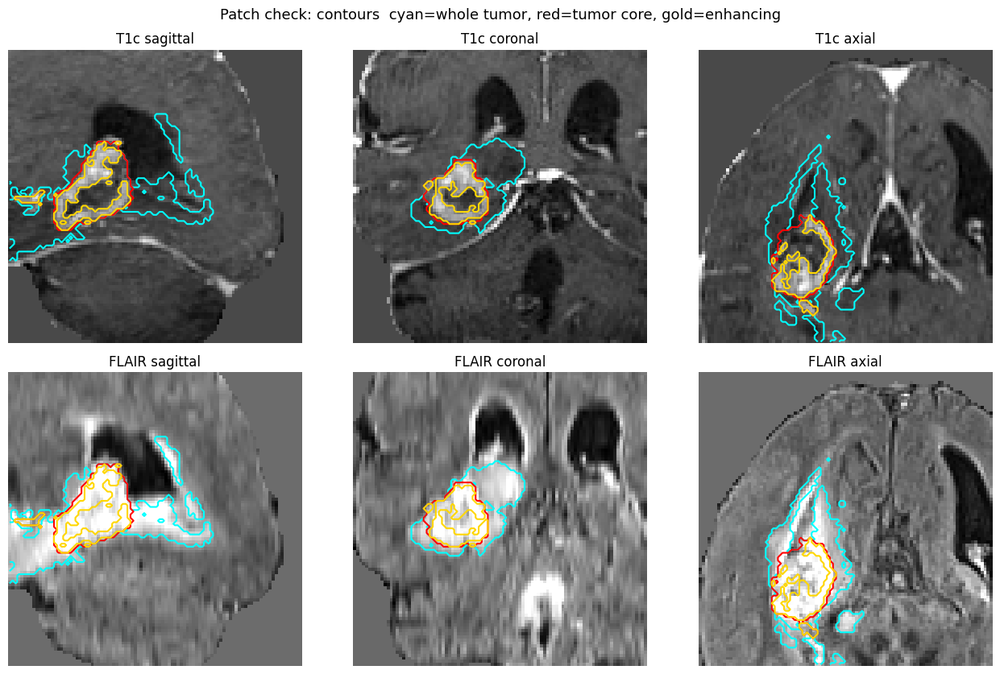

In [ ]:
# ============================================================
# Cell 4: Crop to brain, normalize, cache, patch dataset + checks
# ============================================================
import json, time, numpy as np, nibabel as nib
from concurrent.futures import ThreadPoolExecutor
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

CACHE = "/content/cache"
os.makedirs(CACHE, exist_ok=True)
with open(f"{WORK}/splits.json") as f:
    manifest = json.load(f)
splits, files = manifest["cases"], manifest["files"]
MODS = ["t1n", "t1c", "t2w", "t2f"]

# ---------- 1) Preprocess one case and cache it ----------
def preprocess(case):
    p_img, p_seg, p_meta = (f"{CACHE}/{case}_{s}" for s in ("img.npy", "seg.npy", "meta.json"))
    if all(os.path.exists(p) for p in (p_img, p_seg, p_meta)):
        return json.load(open(p_meta))
    vols = [nib.load(f"{DATA}/{files[case][m]}") for m in MODS]
    seg_nii = nib.load(f"{DATA}/{files[case]['seg']}")
    img = np.stack([v.get_fdata(dtype=np.float32) for v in vols])            # (4, X, Y, Z)
    seg = np.rint(np.asarray(seg_nii.dataobj)).astype(np.uint8)
    seg[seg == 4] = 3                                                         # safety remap
    brain = (img != 0).any(axis=0)
    idx = np.argwhere(brain)
    lo = np.maximum(idx.min(0) - 2, 0)
    hi = np.minimum(idx.max(0) + 3, brain.shape)
    sl = tuple(slice(a, b) for a, b in zip(lo, hi))
    img, seg, brain = img[(slice(None),) + sl], seg[sl], brain[sl]
    for c in range(4):
        ch = img[c]
        ch = np.minimum(ch, np.percentile(ch[brain], 99.5))
        v = ch[brain]
        ch[brain] = (v - v.mean()) / (v.std() + 1e-6)
        ch[~brain] = 0
        img[c] = ch
    np.save(p_img, img.astype(np.float16))
    np.save(p_seg, seg)
    meta = {"case": case, "orig_shape": list(seg_nii.shape), "lo": lo.tolist(), "hi": hi.tolist(),
            "cropped_shape": list(seg.shape), "spacing": [float(z) for z in seg_nii.header.get_zooms()],
            "tumor_frac": float((seg > 0).mean()), "affine": seg_nii.affine.tolist()}
    json.dump(meta, open(p_meta, "w"))
    return meta

all_cases = [c for s in ("train", "val", "test") for c in splits[s]]
t0 = time.time()
with ThreadPoolExecutor(4) as ex:
    metas = list(ex.map(preprocess, all_cases))
meta = {m["case"]: m for m in metas}
print(f"Preprocessed {len(meta)} cases in {time.time() - t0:.0f}s")

shapes = np.array([m["cropped_shape"] for m in metas])
cache_gb = sum(os.path.getsize(f"{CACHE}/{f}") for f in os.listdir(CACHE)) / 1e9
print(f"Cropped shape range  : min {shapes.min(0).tolist()}  max {shapes.max(0).tolist()}")
print(f"Tumor voxels in crop : mean {np.mean([m['tumor_frac'] for m in metas]):.1%} "
      f"(min {min(m['tumor_frac'] for m in metas):.1%}, max {max(m['tumor_frac'] for m in metas):.1%})")
print(f"Cache size           : {cache_gb:.2f} GB")
json.dump(meta, open(f"{WORK}/case_meta.json", "w"))

# ---------- 2) Helpers ----------
def load_case(case):
    img = np.load(f"{CACHE}/{case}_img.npy").astype(np.float32)
    seg = np.load(f"{CACHE}/{case}_seg.npy")
    return img, seg

def to_regions(seg):
    """labels (X,Y,Z) -> 3 overlapping regions: whole tumor, tumor core, enhancing tumor"""
    return np.stack([seg > 0, (seg == 1) | (seg == 3), seg == 3]).astype(np.float32)

# ---------- 3) Patch dataset ----------
PATCH = np.array([96, 96, 96])

class PatchDataset(Dataset):
    def __init__(self, cases, samples_per_case=4, fg_prob=2 / 3, augment=True, seed=None):
        self.cases, self.spc, self.fg_prob, self.augment = cases, samples_per_case, fg_prob, augment
        self.imgs = [np.load(f"{CACHE}/{c}_img.npy", mmap_mode="r") for c in cases]
        self.segs = [np.load(f"{CACHE}/{c}_seg.npy", mmap_mode="r") for c in cases]
        rng = np.random.default_rng(0)
        self.fg = []
        for s in self.segs:
            pts = np.argwhere(np.asarray(s) > 0)
            self.fg.append(pts[rng.choice(len(pts), min(len(pts), 20000), replace=False)] if len(pts) else pts)
    def __len__(self):
        return len(self.cases) * self.spc
    def __getitem__(self, i):
        rng = np.random.default_rng()
        k = i % len(self.cases)
        img, seg = self.imgs[k], self.segs[k]
        shape = np.array(seg.shape)
        if len(self.fg[k]) and rng.random() < self.fg_prob:
            center = self.fg[k][rng.integers(len(self.fg[k]))]
        else:
            center = np.array([rng.integers(s) for s in shape])
        start = np.clip(center - PATCH // 2, 0, np.maximum(shape - PATCH, 0))
        sl = tuple(slice(a, a + p) for a, p in zip(start, PATCH))
        x = np.asarray(img[(slice(None),) + sl], dtype=np.float32)
        y = to_regions(np.asarray(seg[sl]))
        pad = [(0, 0)] + [(0, int(p - s)) for p, s in zip(PATCH, x.shape[1:])]
        if any(b for _, b in pad):
            x, y = np.pad(x, pad), np.pad(y, pad)
        if self.augment:
            for ax in (1, 2, 3):
                if rng.random() < 0.5:
                    x, y = np.flip(x, ax), np.flip(y, ax)
            m = x != 0
            x = np.where(m, x * rng.uniform(0.9, 1.1, (4, 1, 1, 1)) + rng.uniform(-0.1, 0.1, (4, 1, 1, 1)), 0)
        return torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)), torch.from_numpy(np.ascontiguousarray(y))

train_ds = PatchDataset(splits["train"], samples_per_case=4)
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2, drop_last=True, persistent_workers=True)
print(f"\nTrain samples per epoch: {len(train_ds)}  ->  {len(train_loader)} batches of 2")

# ---------- 4) Check batch shapes, foreground balance, speed ----------
t0 = time.time()
fg_frac, any_tumor = [], []
for b, (x, y) in enumerate(train_loader):
    if b == 0:
        print("Image batch:", tuple(x.shape), x.dtype, "| Label batch:", tuple(y.shape), y.dtype)
        print("Image value range:", float(x.min()), "to", float(x.max()))
    fg_frac.append(y.mean(dim=(2, 3, 4)).numpy())
    any_tumor.append((y[:, 0].sum(dim=(1, 2, 3)) > 0).numpy())
    if b == 49:
        break
fg_frac, any_tumor = np.concatenate(fg_frac), np.concatenate(any_tumor)
print(f"Loader speed: {(time.time() - t0) / 50:.2f}s per batch (50 batches)")
print(f"Patches containing tumor : {any_tumor.mean():.0%}")
print(f"Mean region fraction in patches -> WT {fg_frac[:, 0].mean():.1%}, TC {fg_frac[:, 1].mean():.1%}, ET {fg_frac[:, 2].mean():.1%}")

# ---------- 5) Visual check: do mask outlines sit on the lesion? ----------
vis = PatchDataset(splits["train"][:1], samples_per_case=1, fg_prob=1.0, augment=False)
x, y = vis[0]
x, y = x.numpy(), y.numpy()
c = (np.argwhere(y[0] > 0).mean(0)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
cols = ["cyan", "red", "gold"]
for r, (ch, name) in enumerate([(1, "T1c"), (3, "FLAIR")]):
    for a, (plane, ttl) in enumerate([((c[0], slice(None), slice(None)), "sagittal"),
                                      ((slice(None), c[1], slice(None)), "coronal"),
                                      ((slice(None), slice(None), c[2]), "axial")]):
        ax = axes[r, a]
        ax.imshow(np.rot90(x[ch][plane]), cmap="gray")
        for k in range(3):
            m = np.rot90(y[k][plane])
            if m.any():
                ax.contour(m, levels=[0.5], colors=cols[k], linewidths=1.5)
        ax.set_title(f"{name} {ttl}"); ax.axis("off")
plt.suptitle("Patch check: contours  cyan=whole tumor, red=tumor core, gold=enhancing", fontsize=13)
plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# Cell 5: SegResNet, loss, full-volume evaluation, smoke test
# ============================================================
import time, numpy as np, torch, torch.nn as nn
from monai.networks.nets import SegResNet
from monai.losses import DiceLoss
from monai.inferers import sliding_window_inference

device = torch.device("cuda")
torch.manual_seed(42)

# ---------- 1) Model ----------
def build_model():
    return SegResNet(spatial_dims=3, init_filters=16, in_channels=4, out_channels=3,
                     dropout_prob=0.2, blocks_down=(1, 2, 2, 4), blocks_up=(1, 1, 1)).to(device)

model = build_model()
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

# ---------- 2) Loss: Dice + BCE on 3 overlapping regions (sigmoid outputs) ----------
dice_loss = DiceLoss(sigmoid=True, squared_pred=True, smooth_nr=0.0, smooth_dr=1e-5)
bce = nn.BCEWithLogitsLoss()
def seg_loss(logits, target):
    return dice_loss(logits, target) + bce(logits, target)

# ---------- 3) Full-volume prediction and evaluation ----------
REGIONS = ["WT", "TC", "ET"]

def dice_np(pred, gt):
    p, g = pred.astype(bool), gt.astype(bool)
    s = p.sum() + g.sum()
    return 1.0 if s == 0 else 2.0 * (p & g).sum() / s

@torch.no_grad()
def predict_volume(net, img_np, overlap=0.5):
    net.eval()
    x = torch.from_numpy(img_np).unsqueeze(0).to(device)
    with torch.amp.autocast("cuda"):
        logits = sliding_window_inference(x, roi_size=(96, 96, 96), sw_batch_size=2,
                                          predictor=net, overlap=overlap, mode="gaussian")
    return torch.sigmoid(logits.float())[0].cpu().numpy()          # (3, X, Y, Z)

def evaluate(net, cases, overlap=0.5):
    per_case = {}
    for c in cases:
        img, seg = load_case(c)
        prob = predict_volume(net, img, overlap)
        gt = to_regions(seg)
        per_case[c] = [dice_np(prob[k] > 0.5, gt[k]) for k in range(3)]
    return np.array(list(per_case.values())).mean(0), per_case

# ---------- 4) Smoke test: 10 training steps (this model is thrown away afterwards) ----------
opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-5)
scaler = torch.amp.GradScaler("cuda")
torch.cuda.reset_peak_memory_stats()
model.train()
it, step_times, losses = iter(train_loader), [], []
for i in range(10):
    x, y = next(it)
    x, y = x.to(device), y.to(device)
    torch.cuda.synchronize(); t0 = time.time()
    opt.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda"):
        out = model(x)
    loss = seg_loss(out.float(), y)
    scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    torch.cuda.synchronize(); step_times.append(time.time() - t0); losses.append(loss.item())
step = float(np.mean(step_times[2:]))
print(f"\nOutput shape        : {tuple(out.shape)}")
print(f"Loss over 10 steps  : {losses[0]:.3f} -> {losses[-1]:.3f}")
print(f"Time per train step : {step:.2f}s   -> about {step * len(train_loader) / 60:.1f} min per epoch ({len(train_loader)} steps)")
print(f"Peak GPU memory     : {torch.cuda.max_memory_allocated() / 1e9:.1f} GB of {torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB")

# ---------- 5) Time a full-volume validation on 1 case ----------
torch.cuda.synchronize(); t0 = time.time()
d, _ = evaluate(model, splits["val"][:1])
torch.cuda.synchronize(); v = time.time() - t0
print(f"Validation, 1 case  : {v:.1f}s   -> about {v * len(splits['val']) / 60:.1f} min for all {len(splits['val'])} val cases")
print(f"(untrained net Dice, ignore: WT {d[0]:.2f}, TC {d[1]:.2f}, ET {d[2]:.2f})")

Parameters: 4,702,227

Output shape        : (2, 3, 96, 96, 96)
Loss over 10 steps  : 1.594 -> 1.343
Time per train step : 0.21s   -> about 0.5 min per epoch (140 steps)
Peak GPU memory     : 2.4 GB of 16 GB
Validation, 1 case  : 0.9s   -> about 0.2 min for all 15 val cases
(untrained net Dice, ignore: WT 0.50, TC 0.03, ET 0.17)


Starting fresh training
Epoch   1/120 | loss 1.2559 | lr 3.0e-04 | 38s
Epoch   2/120 | loss 1.0768 | lr 3.0e-04 | 38s
Epoch   3/120 | loss 0.9203 | lr 3.0e-04 | 39s
Epoch   4/120 | loss 0.7421 | lr 3.0e-04 | 40s | VAL Dice WT 0.702 TC 0.525 ET 0.517 (mean 0.581)  <- best, saved
Epoch   5/120 | loss 0.5921 | lr 3.0e-04 | 40s
Epoch   6/120 | loss 0.4730 | lr 3.0e-04 | 39s
Epoch   7/120 | loss 0.3950 | lr 3.0e-04 | 40s
Epoch   8/120 | loss 0.3461 | lr 3.0e-04 | 39s | VAL Dice WT 0.825 TC 0.682 ET 0.715 (mean 0.741)  <- best, saved
Epoch   9/120 | loss 0.3075 | lr 3.0e-04 | 40s
Epoch  10/120 | loss 0.2924 | lr 2.9e-04 | 39s
Epoch  11/120 | loss 0.2621 | lr 2.9e-04 | 39s
Epoch  12/120 | loss 0.2550 | lr 2.9e-04 | 39s | VAL Dice WT 0.849 TC 0.687 ET 0.763 (mean 0.766)  <- best, saved
Epoch  13/120 | loss 0.2552 | lr 2.9e-04 | 40s
Epoch  14/120 | loss 0.2205 | lr 2.9e-04 | 40s
Epoch  15/120 | loss 0.2041 | lr 2.9e-04 | 39s
Epoch  16/120 | loss 0.2178 | lr 2.9e-04 | 39s | VAL Dice WT 0.851 TC 

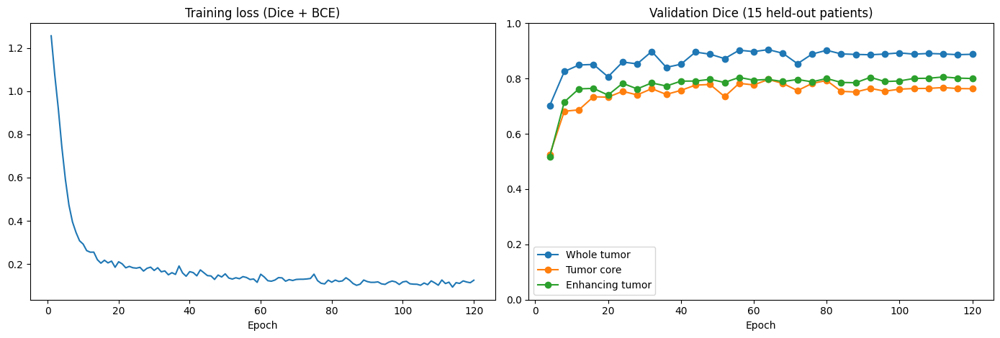

In [ ]:
# ============================================================
# Cell 6: Train SegResNet (resumable) with periodic full-volume validation
# ============================================================
import time, json, numpy as np, torch
import matplotlib.pyplot as plt

EPOCHS, VAL_EVERY = 120, 4
CKPT_LAST, CKPT_BEST = f"{WORK}/seg_last.pt", f"{WORK}/seg_best.pt"

torch.manual_seed(42)
model = build_model()
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda")

hist = {"epoch": [], "train_loss": [], "val_epoch": [], "val_dice": []}
best, start = -1.0, 0

# ---------- Resume if a checkpoint exists ----------
if os.path.exists(CKPT_LAST):
    ck = torch.load(CKPT_LAST, map_location=device)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    hist, best, start = ck["hist"], ck["best"], ck["epoch"]
    print(f"Resumed from epoch {start} (best mean Dice so far {best:.4f})")
else:
    print("Starting fresh training")

def save_last(epoch):
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "hist": hist, "best": best, "epoch": epoch}, CKPT_LAST)

t_start = time.time()
for epoch in range(start, EPOCHS):
    model.train()
    t0, run, n = time.time(), 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            out = model(x)
        loss = seg_loss(out.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 12.0)
        scaler.step(opt); scaler.update()
        run += loss.item(); n += 1
    sched.step()
    hist["epoch"].append(epoch + 1); hist["train_loss"].append(run / n)
    line = f"Epoch {epoch+1:3d}/{EPOCHS} | loss {run/n:.4f} | lr {sched.get_last_lr()[0]:.1e} | {time.time()-t0:.0f}s"

    if (epoch + 1) % VAL_EVERY == 0 or epoch + 1 == EPOCHS:
        d, _ = evaluate(model, splits["val"])
        mean = float(d.mean())
        hist["val_epoch"].append(epoch + 1); hist["val_dice"].append([float(v) for v in d])
        line += f" | VAL Dice WT {d[0]:.3f} TC {d[1]:.3f} ET {d[2]:.3f} (mean {mean:.3f})"
        if mean > best:
            best = mean
            torch.save({"model": model.state_dict(), "epoch": epoch + 1, "val_dice": [float(v) for v in d],
                        "mean_dice": mean}, CKPT_BEST)
            line += "  <- best, saved"
    print(line)
    if (epoch + 1) % 2 == 0 or epoch + 1 == EPOCHS:
        save_last(epoch + 1)

print(f"\nTraining finished in {(time.time() - t_start)/60:.1f} min this session. Best mean val Dice: {best:.4f}")

# ---------- Curves ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(hist["epoch"], hist["train_loss"]); ax[0].set_title("Training loss (Dice + BCE)"); ax[0].set_xlabel("Epoch")
vd = np.array(hist["val_dice"])
for k, name in enumerate(["Whole tumor", "Tumor core", "Enhancing tumor"]):
    ax[1].plot(hist["val_epoch"], vd[:, k], marker="o", label=name)
ax[1].set_title("Validation Dice (15 held-out patients)"); ax[1].set_xlabel("Epoch"); ax[1].set_ylim(0, 1); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{WORK}/seg_training_curves.png", dpi=150); plt.show()

In [ ]:
# ============================================================
# RESTORE: rebuild session state after a Colab reset (no training)
# ============================================================
!pip install -q monai nibabel huggingface_hub

import os, json, subprocess, numpy as np, nibabel as nib, torch
from concurrent.futures import ThreadPoolExecutor
from google.colab import drive
from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference

drive.mount("/content/drive")
device = torch.device("cuda")

WORK = "/content/drive/MyDrive/neuroscan-ai/segmentation"
DATA, CACHE = "/content/brats", "/content/cache"
TAR = f"{WORK}/brats_subset.tar"
CKPT_LAST, CKPT_BEST = f"{WORK}/seg_last.pt", f"{WORK}/seg_best.pt"
MODS = ["t1n", "t1c", "t2w", "t2f"]
os.makedirs(CACHE, exist_ok=True)

# ---------- 1) Check what is on Drive ----------
for p in (CKPT_BEST, CKPT_LAST, TAR, f"{WORK}/splits.json", f"{WORK}/case_meta.json"):
    print(f"{'OK     ' if os.path.exists(p) else 'MISSING'} {os.path.basename(p)}")

# ---------- 2) Splits and file map ----------
manifest = json.load(open(f"{WORK}/splits.json"))
splits, files = manifest["cases"], manifest["files"]
meta = json.load(open(f"{WORK}/case_meta.json"))

# ---------- 3) Restore the raw data from the Drive archive ----------
need = [p for c in splits["test"] for p in files[c].values()]
if not all(os.path.exists(f"{DATA}/{p}") for p in need):
    print("Restoring data from Drive archive (about 1 GB)...")
    subprocess.run(["tar", "-xf", TAR, "-C", "/content"], check=True)
print("Raw data present:", all(os.path.exists(f"{DATA}/{p}") for p in need))

# ---------- 4) Same preprocessing as before (crop, per-modality z-score), test cases only ----------
def preprocess(case):
    p_img, p_seg = f"{CACHE}/{case}_img.npy", f"{CACHE}/{case}_seg.npy"
    if os.path.exists(p_img) and os.path.exists(p_seg):
        return
    vols = [nib.load(f"{DATA}/{files[case][m]}") for m in MODS]
    seg_nii = nib.load(f"{DATA}/{files[case]['seg']}")
    img = np.stack([v.get_fdata(dtype=np.float32) for v in vols])
    seg = np.rint(np.asarray(seg_nii.dataobj)).astype(np.uint8)
    seg[seg == 4] = 3
    brain = (img != 0).any(axis=0)
    idx = np.argwhere(brain)
    lo = np.maximum(idx.min(0) - 2, 0)
    hi = np.minimum(idx.max(0) + 3, brain.shape)
    sl = tuple(slice(a, b) for a, b in zip(lo, hi))
    img, seg, brain = img[(slice(None),) + sl], seg[sl], brain[sl]
    for c in range(4):
        ch = img[c]
        ch = np.minimum(ch, np.percentile(ch[brain], 99.5))
        v = ch[brain]
        ch[brain] = (v - v.mean()) / (v.std() + 1e-6)
        ch[~brain] = 0
        img[c] = ch
    np.save(p_img, img.astype(np.float16))
    np.save(p_seg, seg)

with ThreadPoolExecutor(4) as ex:
    list(ex.map(preprocess, splits["test"]))
print("Test cases preprocessed:", len(splits["test"]))

# ---------- 5) Helpers (identical to the earlier cells) ----------
def load_case(case):
    return np.load(f"{CACHE}/{case}_img.npy").astype(np.float32), np.load(f"{CACHE}/{case}_seg.npy")

def to_regions(seg):
    return np.stack([seg > 0, (seg == 1) | (seg == 3), seg == 3]).astype(np.float32)

def build_model():
    return SegResNet(spatial_dims=3, init_filters=16, in_channels=4, out_channels=3,
                     dropout_prob=0.2, blocks_down=(1, 2, 2, 4), blocks_up=(1, 1, 1)).to(device)

def dice_np(pred, gt):
    p, g = pred.astype(bool), gt.astype(bool)
    s = p.sum() + g.sum()
    return 1.0 if s == 0 else 2.0 * (p & g).sum() / s

@torch.no_grad()
def predict_volume(net, img_np, overlap=0.5):
    net.eval()
    x = torch.from_numpy(img_np).unsqueeze(0).to(device)
    with torch.amp.autocast("cuda"):
        logits = sliding_window_inference(x, roi_size=(96, 96, 96), sw_batch_size=2,
                                          predictor=net, overlap=overlap, mode="gaussian")
    return torch.sigmoid(logits.float())[0].cpu().numpy()

print("\nGPU:", torch.cuda.get_device_name(0), "| ready to run the test evaluation")

Mounted at /content/drive
OK      seg_best.pt
OK      seg_last.pt
OK      brats_subset.tar
OK      splits.json
OK      case_meta.json
Restoring data from Drive archive (about 1 GB)...
Raw data present: True
Test cases preprocessed: 15

GPU: Tesla T4 | ready to run the test evaluation


Loaded best checkpoint: epoch 64, validation mean Dice 0.8327

TEST SET: 15 patients never used for training or checkpoint selection
                             WT     TC     ET
Dice mean                 0.908  0.903  0.819
Dice std                  0.069  0.103  0.235
Dice median               0.919  0.922  0.879
Dice min                  0.734  0.574  0.000
IoU mean                  0.838  0.836  0.734
Sensitivity               0.938  0.949  0.904
Precision                 0.885  0.881  0.805
Volume corr               0.987  0.911  0.961
Mean abs vol error (cm3)  6.315  8.382  2.588

Mean Dice over WT/TC/ET: 0.876   (validation, selected checkpoint: 0.833)
Patients with no enhancing tumor in the ground truth: 1

Per-patient Dice and whole-tumor volumes:
                     WT Dice  TC Dice  ET Dice  WT true cm3  WT pred cm3
case                                                                    
BraTS-GLI-01233-000    0.904    0.911    0.870       87.609       85.729
BraTS-GLI-0115

/tmp/ipykernel_2416/1806718889.py:68: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df[f"{r}_dice"] for r in REGIONS], labels=["Whole tumor", "Tumor core", "Enhancing tumor"], showmeans=True)


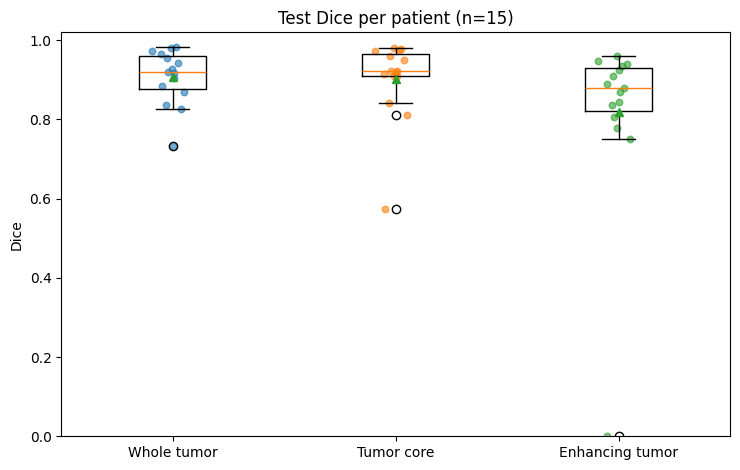

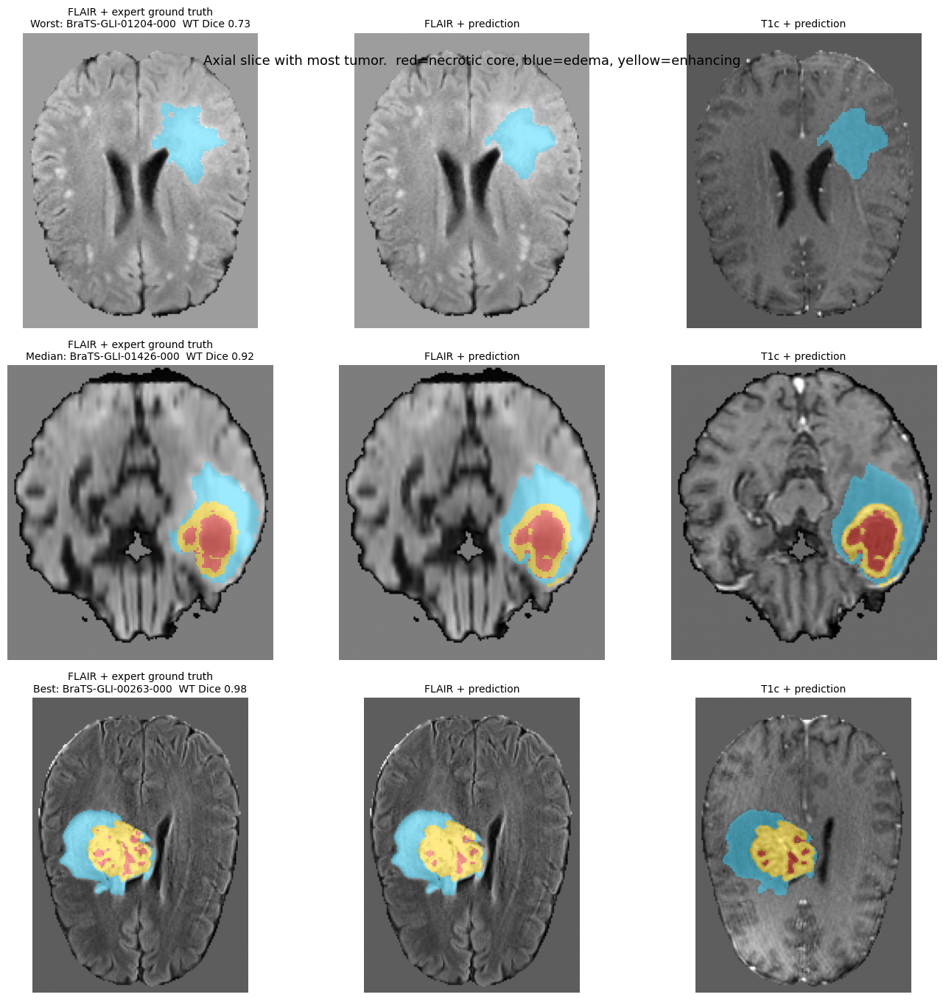

In [ ]:
# ============================================================
# Cell 7: Test-set evaluation of the best checkpoint (15 unseen patients)
# ============================================================
import json, numpy as np, torch, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ck = torch.load(CKPT_BEST, map_location=device)
model = build_model()
model.load_state_dict(ck["model"])
model.eval()
print(f"Loaded best checkpoint: epoch {ck['epoch']}, validation mean Dice {ck['mean_dice']:.4f}")

REGIONS = ["WT", "TC", "ET"]
rows, preds = [], {}
for c in splits["test"]:
    img, seg = load_case(c)
    prob = predict_volume(model, img, overlap=0.5)
    gt = to_regions(seg)
    pr = prob > 0.5
    preds[c] = pr
    vox_cm3 = float(np.prod(meta[c]["spacing"])) / 1000.0
    row = {"case": c}
    for k, r in enumerate(REGIONS):
        p, g = pr[k], gt[k].astype(bool)
        inter = (p & g).sum()
        row[f"{r}_dice"] = dice_np(p, g)                       # both empty -> 1.0 (BraTS convention)
        row[f"{r}_iou"] = 1.0 if (p | g).sum() == 0 else inter / (p | g).sum()
        row[f"{r}_sens"] = np.nan if g.sum() == 0 else inter / g.sum()
        row[f"{r}_prec"] = np.nan if p.sum() == 0 else inter / p.sum()
        row[f"{r}_vol_true"] = g.sum() * vox_cm3
        row[f"{r}_vol_pred"] = p.sum() * vox_cm3
    rows.append(row)
df = pd.DataFrame(rows).set_index("case")

# ---------- Summary table ----------
summary = {}
for r in REGIONS:
    summary[r] = {
        "Dice mean": df[f"{r}_dice"].mean(), "Dice std": df[f"{r}_dice"].std(),
        "Dice median": df[f"{r}_dice"].median(), "Dice min": df[f"{r}_dice"].min(),
        "IoU mean": df[f"{r}_iou"].mean(),
        "Sensitivity": df[f"{r}_sens"].mean(), "Precision": df[f"{r}_prec"].mean(),
        "Volume corr": np.corrcoef(df[f"{r}_vol_true"], df[f"{r}_vol_pred"])[0, 1],
        "Mean abs vol error (cm3)": (df[f"{r}_vol_pred"] - df[f"{r}_vol_true"]).abs().mean(),
    }
sm = pd.DataFrame(summary)
print(f"\nTEST SET: {len(df)} patients never used for training or checkpoint selection")
print(sm.round(3).to_string())
print(f"\nMean Dice over WT/TC/ET: {np.mean([df[f'{r}_dice'].mean() for r in REGIONS]):.3f}   "
      f"(validation, selected checkpoint: {ck['mean_dice']:.3f})")
print("Patients with no enhancing tumor in the ground truth:", int((df["ET_vol_true"] == 0).sum()))

print("\nPer-patient Dice and whole-tumor volumes:")
show = df[["WT_dice", "TC_dice", "ET_dice", "WT_vol_true", "WT_vol_pred"]].round(3)
show.columns = ["WT Dice", "TC Dice", "ET Dice", "WT true cm3", "WT pred cm3"]
print(show.to_string())

# ---------- Save numbers for the README ----------
out = {"checkpoint_epoch": int(ck["epoch"]), "val_mean_dice": float(ck["mean_dice"]),
       "n_test_patients": int(len(df)), "summary": {k: {m: float(v) for m, v in d.items()} for k, d in summary.items()},
       "per_case": df.reset_index().to_dict(orient="records")}
json.dump(out, open(f"{WORK}/seg_test_metrics.json", "w"), indent=1, default=float)
df.to_csv(f"{WORK}/seg_test_per_patient.csv")

# ---------- Figure 1: Dice distribution ----------
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.boxplot([df[f"{r}_dice"] for r in REGIONS], labels=["Whole tumor", "Tumor core", "Enhancing tumor"], showmeans=True)
for i, r in enumerate(REGIONS, 1):
    ax.scatter(np.random.default_rng(0).normal(i, 0.04, len(df)), df[f"{r}_dice"], alpha=0.6, s=22)
ax.set_ylim(0, 1.02); ax.set_ylabel("Dice"); ax.set_title(f"Test Dice per patient (n={len(df)})")
plt.tight_layout(); plt.savefig(f"{WORK}/seg_test_dice_boxplot.png", dpi=150); plt.show()

# ---------- Figure 2: best / median / worst cases (by whole-tumor Dice) ----------
order = df["WT_dice"].sort_values().index.tolist()
picks = [("Worst", order[0]), ("Median", order[len(order) // 2]), ("Best", order[-1])]
cmap = ListedColormap(["none", "#ff3b30", "#39d5ff", "#ffd60a"])   # necrotic, edema, enhancing

def to_labels(reg):
    lab = np.zeros(reg.shape[1:], np.uint8)
    lab[reg[0]] = 2; lab[reg[1]] = 1; lab[reg[2]] = 3
    return lab

fig, axes = plt.subplots(3, 3, figsize=(14, 14))
for r, (tag, c) in enumerate(picks):
    img, seg = load_case(c)
    z = int(np.argmax((seg > 0).sum(axis=(0, 1))))
    lab_p = to_labels(preds[c])
    for col, (bg, lab, ttl) in enumerate([(3, seg, "FLAIR + expert ground truth"),
                                          (3, lab_p, "FLAIR + prediction"),
                                          (1, lab_p, "T1c + prediction")]):
        ax = axes[r, col]
        ax.imshow(np.rot90(img[bg][:, :, z]), cmap="gray")
        ax.imshow(np.rot90(lab[:, :, z]), cmap=cmap, vmin=0, vmax=3, alpha=0.5, interpolation="nearest")
        ax.axis("off")
        ax.set_title(f"{ttl}" + (f"\n{tag}: {c}  WT Dice {df.loc[c, 'WT_dice']:.2f}" if col == 0 else ""), fontsize=10)
plt.suptitle("Axial slice with most tumor.  red=necrotic core, blue=edema, yellow=enhancing", fontsize=13, y=0.92)
plt.tight_layout(); plt.savefig(f"{WORK}/seg_test_examples.png", dpi=150); plt.show()

In [ ]:
# ============================================================
# Cell 8: Export weights, write standalone CPU module, test it
# ============================================================
import os, time, importlib.util
import numpy as np, nibabel as nib, torch

DEPLOY = f"{WORK}/deploy_seg"
os.makedirs(DEPLOY, exist_ok=True)

# ---------- 1) Clean weights bundle ----------
ck = torch.load(CKPT_BEST, map_location="cpu")
bundle = {
    "state_dict": {k: v.cpu() for k, v in ck["model"].items()},
    "arch": {"spatial_dims": 3, "init_filters": 16, "in_channels": 4, "out_channels": 3,
             "dropout_prob": 0.2, "blocks_down": [1, 2, 2, 4], "blocks_up": [1, 1, 1]},
    "modalities": ["t1n", "t1c", "t2w", "t2f"],
    "regions": ["WT", "TC", "ET"],
    "roi": [96, 96, 96],
    "epoch": int(ck["epoch"]),
}
torch.save(bundle, f"{DEPLOY}/NeuroScan_Seg3D_SegResNet.pth")
print(f"Weights saved: {os.path.getsize(f'{DEPLOY}/NeuroScan_Seg3D_SegResNet.pth') / 1e6:.1f} MB (epoch {bundle['epoch']})")

# ---------- 2) Standalone inference module ----------
module_code = r'''
"""NeuroScan AI - 3D brain tumor segmentation (SegResNet, BraTS 2023 GLI). CPU inference."""
import numpy as np
import nibabel as nib
import torch
from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference

MODS = ["t1n", "t1c", "t2w", "t2f"]


class SegmentationError(ValueError):
    """Raised for inputs the model cannot handle (message is safe to show to users)."""


class TumorSegmenter:
    def __init__(self, weights_path, device="cpu"):
        b = torch.load(weights_path, map_location=device, weights_only=True)
        a = b["arch"]
        self.net = SegResNet(
            spatial_dims=a["spatial_dims"], init_filters=a["init_filters"],
            in_channels=a["in_channels"], out_channels=a["out_channels"],
            dropout_prob=a["dropout_prob"], blocks_down=tuple(a["blocks_down"]),
            blocks_up=tuple(a["blocks_up"]),
        )
        self.net.load_state_dict(b["state_dict"])
        self.net.to(device).eval()
        self.device = device
        self.roi = tuple(b["roi"])
        self.epoch = b["epoch"]

    @staticmethod
    def load_inputs(paths):
        """paths: dict modality -> NIfTI file path. Returns (array(4,X,Y,Z), spacing, affine)."""
        missing = [m for m in MODS if m not in paths]
        if missing:
            raise SegmentationError("Missing MRI sequence(s): " + ", ".join(m.upper() for m in missing)
                                    + ". The model needs T1n, T1c, T2w and T2-FLAIR (t2f).")
        try:
            imgs = [nib.load(paths[m]) for m in MODS]
        except Exception:
            raise SegmentationError("Could not read one of the files as NIfTI (.nii or .nii.gz).")
        shape = imgs[0].shape
        if len(shape) != 3:
            raise SegmentationError("Each file must be a single 3D volume.")
        if max(shape) > 320 or min(shape) < 64:
            raise SegmentationError(f"Unexpected volume size {shape}; BraTS-style volumes (about 240x240x155) are expected.")
        for m, im in zip(MODS, imgs):
            if im.shape != shape or not np.allclose(im.affine, imgs[0].affine, atol=1e-3):
                raise SegmentationError(f"{m.upper()} is not co-registered with the other sequences (different shape or geometry).")
        spacing = tuple(float(z) for z in imgs[0].header.get_zooms()[:3])
        if max(abs(s - 1.0) for s in spacing) > 0.1:
            raise SegmentationError(f"Voxel spacing {spacing} mm; the model expects 1 mm isotropic (BraTS preprocessing).")
        codes = "".join(nib.aff2axcodes(imgs[0].affine))
        if codes != "LPS":
            raise SegmentationError(f"Orientation {codes} is not supported; the model was trained on BraTS files in LPS orientation.")
        arr = np.stack([im.get_fdata(dtype=np.float32) for im in imgs])
        return arr, spacing, imgs[0].affine

    @staticmethod
    def preprocess(arr):
        """Crop to the brain, clip at the 99.5th percentile, z-score each sequence inside the brain."""
        brain = (arr != 0).any(axis=0)
        if brain.sum() < 100000:
            raise SegmentationError("The volume looks empty or not skull-stripped (BraTS-style, skull-stripped input is expected).")
        idx = np.argwhere(brain)
        lo = np.maximum(idx.min(0) - 2, 0)
        hi = np.minimum(idx.max(0) + 3, brain.shape)
        sl = tuple(slice(a, b) for a, b in zip(lo, hi))
        img = arr[(slice(None),) + sl].copy()
        brain = brain[sl]
        for c in range(4):
            ch = img[c]
            ch = np.minimum(ch, np.percentile(ch[brain], 99.5))
            v = ch[brain]
            ch[brain] = (v - v.mean()) / (v.std() + 1e-6)
            ch[~brain] = 0
            img[c] = ch
        return img, lo, hi

    @torch.no_grad()
    def predict(self, paths, overlap=0.5, threshold=0.5):
        arr, spacing, affine = self.load_inputs(paths)
        full_shape = arr.shape[1:]
        img, lo, hi = self.preprocess(arr)
        x = torch.from_numpy(img).unsqueeze(0).to(self.device)
        logits = sliding_window_inference(x, roi_size=self.roi, sw_batch_size=1, predictor=self.net,
                                          overlap=overlap, mode="gaussian")
        reg = (torch.sigmoid(logits.float())[0].cpu().numpy() > threshold)      # (3, crop): WT, TC, ET
        lab_c = np.zeros(reg.shape[1:], np.uint8)                               # 1 necrotic, 2 edema, 3 enhancing
        lab_c[reg[0]] = 2
        lab_c[reg[1]] = 1
        lab_c[reg[2]] = 3
        labels = np.zeros(full_shape, np.uint8)
        labels[tuple(slice(a, b) for a, b in zip(lo, hi))] = lab_c
        vox = float(np.prod(spacing)) / 1000.0
        return {
            "labels": labels,
            "regions_cropped": reg,
            "crop": (lo.tolist(), hi.tolist()),
            "shape": tuple(full_shape),
            "spacing": spacing,
            "affine": affine,
            "volumes_cm3": {
                "whole_tumor": round(int(reg[0].sum()) * vox, 2),
                "tumor_core": round(int(reg[1].sum()) * vox, 2),
                "enhancing_tumor": round(int(reg[2].sum()) * vox, 2),
            },
        }
'''
with open(f"{DEPLOY}/seg_infer.py", "w") as f:
    f.write(module_code.strip() + "\n")
print("Wrote seg_infer.py")

# ---------- 3) Load the module and test on one test patient ----------
spec = importlib.util.spec_from_file_location("seg_infer", f"{DEPLOY}/seg_infer.py")
mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
seg_cpu = mod.TumorSegmenter(f"{DEPLOY}/NeuroScan_Seg3D_SegResNet.pth", device="cpu")

CASE = splits["test"][0]
paths = {m: f"{DATA}/{files[CASE][m]}" for m in mod.MODS}
gt_full = np.rint(np.asarray(nib.load(f"{DATA}/{files[CASE]['seg']}").dataobj)).astype(np.uint8)
gt_vox = 0.001
print(f"\nTest patient {CASE}")
print("Expert volumes (cm3): WT %.2f  TC %.2f  ET %.2f" % (
    (gt_full > 0).sum() * gt_vox, ((gt_full == 1) | (gt_full == 3)).sum() * gt_vox, (gt_full == 3).sum() * gt_vox))

# GPU reference with the notebook pipeline
gpu_net = build_model(); gpu_net.load_state_dict(ck["model"])
gpu_reg = predict_volume(gpu_net, load_case(CASE)[0], overlap=0.5) > 0.5

for ov in (0.5, 0.25):
    t0 = time.time()
    out = seg_cpu.predict(paths, overlap=ov)
    dt = time.time() - t0
    agree = [dice_np(out["regions_cropped"][k], gpu_reg[k]) for k in range(3)]
    print(f"\nCPU overlap={ov}: {dt:.1f}s | volumes cm3 {out['volumes_cm3']}")
    print(f"   agreement with GPU pipeline (Dice) WT {agree[0]:.4f} TC {agree[1]:.4f} ET {agree[2]:.4f}")
print("\nOutput label volume:", out["labels"].shape, out["labels"].dtype,
      "| original shape:", tuple(meta[CASE]["orig_shape"]))
print("Whole-tumor Dice vs expert mask, in the ORIGINAL geometry (checks the paste-back):",
      round(float(dice_np(out["labels"] > 0, gt_full > 0)), 4))

# ---------- 4) How does it handle a bad upload? ----------
try:
    seg_cpu.predict({m: p for m, p in paths.items() if m != "t2f"})
except mod.SegmentationError as e:
    print("\nMissing-sequence upload ->", e)

Weights saved: 18.8 MB (epoch 64)
Wrote seg_infer.py

Test patient BraTS-GLI-01233-000
Expert volumes (cm3): WT 87.61  TC 28.73  ET 22.11

CPU overlap=0.5: 52.1s | volumes cm3 {'whole_tumor': 85.74, 'tumor_core': 28.16, 'enhancing_tumor': 22.82}
   agreement with GPU pipeline (Dice) WT 0.9999 TC 0.9999 ET 0.9999

CPU overlap=0.25: 31.9s | volumes cm3 {'whole_tumor': 85.29, 'tumor_core': 28.26, 'enhancing_tumor': 22.94}
   agreement with GPU pipeline (Dice) WT 0.9947 TC 0.9947 ET 0.9916

Output label volume: (240, 240, 155) uint8 | original shape: (240, 240, 155)
Whole-tumor Dice vs expert mask, in the ORIGINAL geometry (checks the paste-back): 0.9031

Missing-sequence upload -> Missing MRI sequence(s): T2F. The model needs T1n, T1c, T2w and T2-FLAIR (t2f).


case                   shape            Dice WT/TC/ET        ET cm3 expert/pred   gzip MB
BraTS-GLI-00263-000    (142, 194, 142)  0.98/0.97/0.94       22.65 /  24.22       3.2   <- Best case
BraTS-GLI-01426-000    (153, 170, 145)  0.92/0.92/0.81       20.42 /  19.37       2.6   <- Median case
BraTS-GLI-01204-000    (133, 167, 139)  0.73/0.92/0.85        3.00 /   3.45       2.2   <- Worst whole-tumor Dice
BraTS-GLI-01499-000    (141, 178, 145)  0.88/0.57/0.00        0.00 /   0.76       2.9   <- No enhancing tumor in expert mask


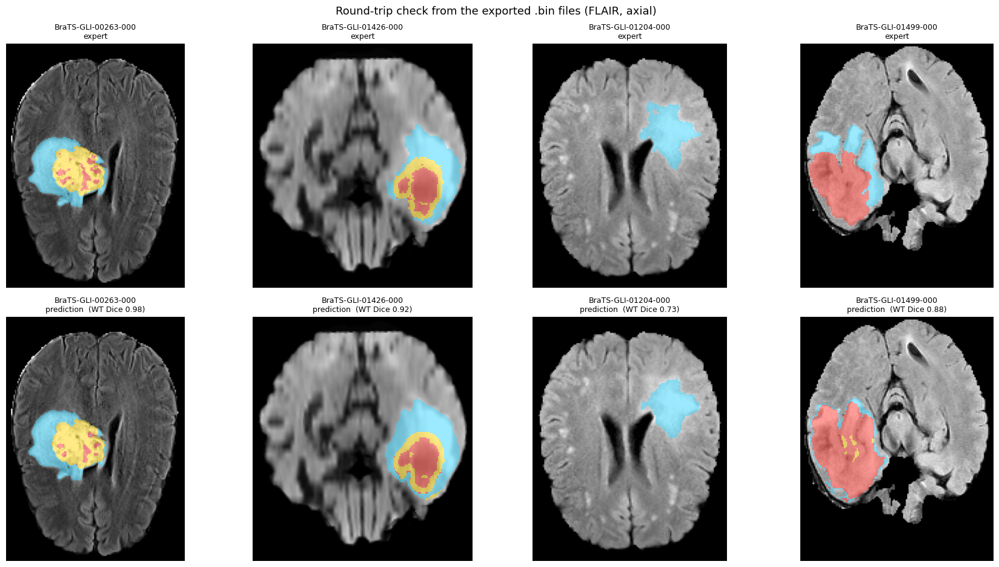


Exported to /content/drive/MyDrive/neuroscan-ai/segmentation/deploy_seg/demo_cases  (57.6 MB uncompressed)


In [ ]:
# ============================================================
# Cell 9: Export 4 test patients as compact viewer bundles + round-trip check
# ============================================================
import json, gzip, numpy as np, nibabel as nib, torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

VIEW = f"{DEPLOY}/demo_cases"
os.makedirs(VIEW, exist_ok=True)

DEMO = {
    "BraTS-GLI-00263-000": "Best case",
    "BraTS-GLI-01426-000": "Median case",
    "BraTS-GLI-01204-000": "Worst whole-tumor Dice",
    "BraTS-GLI-01499-000": "No enhancing tumor in expert mask",
}
assert all(c in splits["test"] for c in DEMO), "demo cases must come from the held-out test split"

net = build_model()
net.load_state_dict(torch.load(CKPT_BEST, map_location=device)["model"])
net.eval()

def to_u8(ch, brain):
    lo_, hi_ = np.percentile(ch[brain], [1, 99.5])
    out = np.clip((ch - lo_) / (hi_ - lo_ + 1e-6), 0, 1) * 254 + 1
    out[~brain] = 0
    return out.astype(np.uint8)

def regions_to_labels(reg):
    lab = np.zeros(reg.shape[1:], np.uint8)       # 1 necrotic core, 2 edema, 3 enhancing
    lab[reg[0]] = 2; lab[reg[1]] = 1; lab[reg[2]] = 3
    return lab

summary = []
for case, tag in DEMO.items():
    m = meta[case]
    lo, hi = m["lo"], m["hi"]
    sl = tuple(slice(a, b) for a, b in zip(lo, hi))

    # raw intensities, cropped, for display only
    raw = {k: nib.load(f"{DATA}/{files[case][k]}").get_fdata(dtype=np.float32)[sl] for k in ("t2f", "t1c")}
    brain = (raw["t2f"] != 0) | (raw["t1c"] != 0)

    # prediction (same pipeline as the notebook evaluation) and expert mask, both cropped
    img, seg = load_case(case)
    pred_reg = predict_volume(net, img, overlap=0.5) > 0.5
    gt_reg = to_regions(seg).astype(bool)
    dices = [float(dice_np(pred_reg[k], gt_reg[k])) for k in range(3)]
    vox = float(np.prod(m["spacing"])) / 1000.0

    d = f"{VIEW}/{case}"
    os.makedirs(d, exist_ok=True)
    arrays = {"flair": to_u8(raw["t2f"], brain), "t1c": to_u8(raw["t1c"], brain),
              "pred": regions_to_labels(pred_reg), "gt": seg.astype(np.uint8)}
    for k, a in arrays.items():
        np.ascontiguousarray(a, dtype=np.uint8).tofile(f"{d}/{k}.bin")       # C-order (X, Y, Z)
    info = {
        "case": case, "title": tag, "shape": list(seg.shape), "order": "C, index = (x*Y + y)*Z + z",
        "spacing_mm": m["spacing"], "orientation": "LPS", "crop_lo": lo, "crop_hi": hi,
        "orig_shape": m["orig_shape"], "labels": {"1": "necrotic core", "2": "edema", "3": "enhancing tumor"},
        "dice": dict(zip(["WT", "TC", "ET"], dices)),
        "volumes_cm3_pred": dict(zip(["WT", "TC", "ET"], [float(pred_reg[k].sum() * vox) for k in range(3)])),
        "volumes_cm3_expert": dict(zip(["WT", "TC", "ET"], [float(gt_reg[k].sum() * vox) for k in range(3)])),
    }
    json.dump(info, open(f"{d}/meta.json", "w"), indent=1)
    gz = sum(len(gzip.compress(open(f"{d}/{k}.bin", "rb").read(), 6)) for k in arrays) / 1e6
    summary.append((case, tag, seg.shape, dices, info["volumes_cm3_expert"]["ET"], info["volumes_cm3_pred"]["ET"], gz))

print(f"{'case':22} {'shape':16} {'Dice WT/TC/ET':20} {'ET cm3 expert/pred':20} {'gzip MB'}")
for case, tag, shp, dc, et_t, et_p, gz in summary:
    print(f"{case:22} {str(shp):16} {dc[0]:.2f}/{dc[1]:.2f}/{dc[2]:.2f}      {et_t:6.2f} / {et_p:6.2f}       {gz:.1f}   <- {tag}")

# ---------- Round trip: read the .bin files back and draw them ----------
cmap = ListedColormap(["none", "#ff3b30", "#39d5ff", "#ffd60a"])
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
for j, case in enumerate(DEMO):
    info = json.load(open(f"{VIEW}/{case}/meta.json"))
    shp = tuple(info["shape"])
    rd = lambda k: np.fromfile(f"{VIEW}/{case}/{k}.bin", dtype=np.uint8).reshape(shp)
    fl, pr, gt = rd("flair"), rd("pred"), rd("gt")
    z = int(np.argmax((gt > 0).sum(axis=(0, 1))))
    for r, (lab, name) in enumerate([(gt, "expert"), (pr, "prediction")]):
        ax = axes[r, j]
        ax.imshow(np.rot90(fl[:, :, z]), cmap="gray")
        ax.imshow(np.rot90(lab[:, :, z]), cmap=cmap, vmin=0, vmax=3, alpha=0.5, interpolation="nearest")
        ax.axis("off")
        ax.set_title(f"{case}\n{name}" + (f"  (WT Dice {info['dice']['WT']:.2f})" if r else ""), fontsize=9)
plt.suptitle("Round-trip check from the exported .bin files (FLAIR, axial)", fontsize=13)
plt.tight_layout(); plt.show()

tot = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(VIEW) for f in fs) / 1e6
print(f"\nExported to {VIEW}  ({tot:.1f} MB uncompressed)")